# Project links

**Github repository**
https://github.com/phkhle/IND320/tree/project3

**Streamlitt app**
https://ind320-h2026.streamlit.app/


In [1]:
import geopandas as gpd

# Download Euro, USD currency exchange rates

# Streamlit application 

## Structure and navigation

For Project 4, the Streamlit dashboard is reorganised according to the purpose of each page rather than only the data source.

The application is divided into three main sections:

- Explore Data: 
    - Interactive Map
    - Reservoir Statistics 
    - Electricity Transfer
    - Currency Exchange.

- Analysis: 
    - STL and Spectrogram
    - Weather Anomalies
    - Sliding Window Correlation.

- Forecasting: Reservoir Filling Forecast.

A separate Home page provides an overview of the dashboard and its data sources.

The navigation was implemented using ``st.navigation()`` and ``st.Page()``. Pages can then be grouped into logical sections.

Shared geographical selections will be stored using ``st.session_state``. Users will be able to select an area on the interactive map and reuse that selection in other analyses.



## Interactive map (XXX)

## Create GeoJSON

Create geographic file for the electricity pricing areas (EL)

In [2]:
# Load electricity price areas
price_areas = gpd.read_file(
    "../data/shapefiles/Budområder.shp"
)

# Convert to WGS84 coordinates
price_areas = price_areas.to_crs(epsg=4326)

# Standardize region names
price_areas["region"] = (
    price_areas["budomr"]
    .str.replace(" ", "", regex=False)
)

# Save as GeoJSON
price_areas[["region", "geometry"]].to_file(
    "../data/price_areas.geojson",
    driver="GeoJSON"
)

print("GeoJSON for electricity price areas created successfully!")

GeoJSON for electricity price areas created successfully!


Create geographic file for the precipitation areas

In [3]:
# Load rain areas
regions = gpd.read_file("../data/shapefiles/NVE_region.shp", encoding = 'utf-8')

# Map NVE administrative regions to precipitation regions
region_mapping = {
    "RS": "Øst",
    "RØ": "Øst",
    "RV": "Vest",
    "RM": "Nord",
    "RN": "Nord"
}

# Assign precipitation region names
precipitation_regions = regions.copy()
precipitation_regions["region"] = precipitation_regions["REGION"].map(region_mapping)

# Merge polygons belonging to the same precipitation region
precipitation_regions = precipitation_regions.dissolve(
    by="region",
    as_index=False
)

# Convert precipitation regions to WGS84
weather_regions_geojson = precipitation_regions.to_crs(epsg=4326)

# Keep only region names and geometry
weather_regions_geojson = weather_regions_geojson[
    ["region", "geometry"]
]

# Export as GeoJSON
weather_regions_geojson.to_file(
    "../data/weather_regions.geojson",
    driver="GeoJSON"
)

print("Weather regions GeoJSON created successfully!")

Weather regions GeoJSON created successfully!


Create geographic file for the water areas (river basin areas - VASS)

In [4]:
# Load water areas
water_regions = gpd.read_file("../data/shapefiles/Vassdragsomrade.shp", encoding = 'utf-8')
# Convert to WGS84 coordinates
water_regions = water_regions.to_crs(epsg=4326)


# Standardize region names
water_regions["region"] = (
    water_regions["vassdragso"]
    .str.replace(" ", "", regex=False)
)

# Save as GeoJSON
water_regions[["region", "geometry"]].to_file(
    "../data/water_areas.geojson",
    driver="GeoJSON"
)


In [5]:
import geopandas as gpd

water_regions = gpd.read_file("../data/water_areas.geojson")

print("Antall områder:", len(water_regions))
print("Kolonner:", water_regions.columns.tolist())

display(water_regions[["region"]])

Antall områder: 205
Kolonner: ['region', 'geometry']


,region
0,196
1,191
2,190
3,189
4,315
...,...
200,005
201,004
202,003
203,002


# Forecasting

In [6]:
import sys
from pathlib import Path

# Get the parent directory, since the notebook is located one folder below the project root
project_root = Path.cwd().parent
# Add the project root to Python's module search path
# This allows Python to find and import modules from src/
sys.path.insert(0, str(project_root))

from src.NVE_API import get_nve_data

from src.forecasting import forecast_reservoir
# Retrieve reservoir data from NVE API
df_nve = get_nve_data()

# Select NO3
df_region = df_nve[
    (df_nve["omrType"] == "EL") &
    (df_nve["omrnr"] == 3)
].copy()

results = forecast_reservoir(
    df=df_region,
    n_lags=4,
    test_weeks=52
)

results.head()

,date,actual,predicted
0,2025-11-23,0.851878,0.866210
1,2025-11-30,0.824069,0.842509
2,2025-12-07,0.795395,0.804163
3,2025-12-14,0.774006,0.767300
4,2025-12-21,0.766409,0.748065


In [7]:
from src.NVE_API import get_nve_data

df_nve = get_nve_data()

# Select NO3
df_region = df_nve[
    (df_nve["omrType"] == "EL") &
    (df_nve["omrnr"] == 3)
].copy()

df_region = df_region.sort_values("dato_Id")

print("First observation:", df_region["dato_Id"].min())
print("Last observation:", df_region["dato_Id"].max())
print("Number of weeks:", len(df_region))

First observation: 1995-01-08 00:00:00
Last observation: 2026-11-15 00:00:00
Number of weeks: 1663


In [8]:
from src.forecasting import forecast_reservoir

results = forecast_reservoir(
    df=df_region,
    n_lags=4,
    test_weeks=52
)

print(results.head())

        date    actual  predicted
0 2025-11-23  0.851878   0.866210
1 2025-11-30  0.824069   0.842509
2 2025-12-07  0.795395   0.804163
3 2025-12-14  0.774006   0.767300
4 2025-12-21  0.766409   0.748065


In [9]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    results["actual"],
    results["predicted"]
)

rmse = np.sqrt(mean_squared_error(
    results["actual"],
    results["predicted"]
))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.0179
RMSE: 0.0218


In [10]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Baseline: previous week's filling
df_region["baseline"] = df_region["fyllingsgrad"].shift(1)

baseline_df = results.merge(
    df_region[["dato_Id", "baseline"]],
    left_on="date",
    right_on="dato_Id",
    how="left"
)

# Remove missing values
baseline_df = baseline_df.dropna(
    subset=["actual", "predicted", "baseline"]
)

# Evaluate both models
evaluation = []

for model_name, pred_col in [
    ("River", "predicted"),
    ("Baseline", "baseline")
]:
    y_true = baseline_df["actual"]
    y_pred = baseline_df[pred_col]

    evaluation.append({
        "Model": model_name,
        "MAE (pp)": mean_absolute_error(y_true, y_pred) * 100,
        "RMSE (pp)": np.sqrt(mean_squared_error(y_true, y_pred)) * 100,
        "R²": r2_score(y_true, y_pred)
    })

evaluation_df = pd.DataFrame(evaluation).set_index("Model")

display(evaluation_df.round(4))

,MAE (pp),RMSE (pp),R²
Model,,,
River,1.7916,2.1807,0.9869
Baseline,2.4360,3.0702,0.9739


The River model outperforms the baseline on all three evaluation metrics.

However, we have so far only evaluated one week ahead, with the model being updated on an ongoing basis.

This means that these results do not tell us how well the model will predict 12 weeks ahead without new observations.
THerefore I extend the model to multi-step forecasting (1–12 weeks ahead).

We can retain the existing River model as a starting point and later compare it with SNARIMAX.

## Historical evaluation of 12 weeks forecasting

the River model works well in the short term, but struggles to predict reservoir levels far into the future.

The model uses only the last four weeks:
n_lags = 4. Consequently, it has limited information about annual seasonal patterns.

### SNARIMAX

In [11]:
from src.forecasting import forecast_reservoir_snarimax

forecast_snarimax = forecast_reservoir_snarimax(
    df=df_region,
    horizon=12,
    p=1,
    d=1,
    q=1,
    m=52,
    sp=1,
    sd=0,
    sq=0
)

display(forecast_snarimax)

,date,predicted
0,2026-11-22,0.673489
1,2026-11-29,0.651231
2,2026-12-06,0.629657
3,2026-12-13,0.610374
4,2026-12-20,0.596018
5,2026-12-27,0.579069
6,2027-01-03,0.557682
7,2027-01-10,0.532450
8,2027-01-17,0.504939
9,2027-01-24,0.474731


In [12]:
from src.forecasting import evaluate_forecasting_models

predictions_df, metrics_df = evaluate_forecasting_models(
    df=df_region,
    horizon=12,
    test_weeks=52,
    n_lags=4
)

display(metrics_df.round(4))

,Model,Horizon,MAE (pp),RMSE (pp),R²
0,Baseline,1,2.7695,3.3503,0.9692
1,River,1,1.9014,2.2927,0.9856
2,SNARIMAX,1,1.1969,1.6407,0.9926
3,Baseline,2,5.2825,6.4790,0.8755
4,River,2,3.3360,4.1206,0.9496
5,SNARIMAX,2,2.6386,3.5491,0.9626
6,Baseline,3,7.7104,9.4100,0.7197
7,River,3,4.7501,5.9540,0.8878
8,SNARIMAX,3,4.0245,5.5035,0.9041
9,Baseline,4,10.1725,12.1780,0.5081


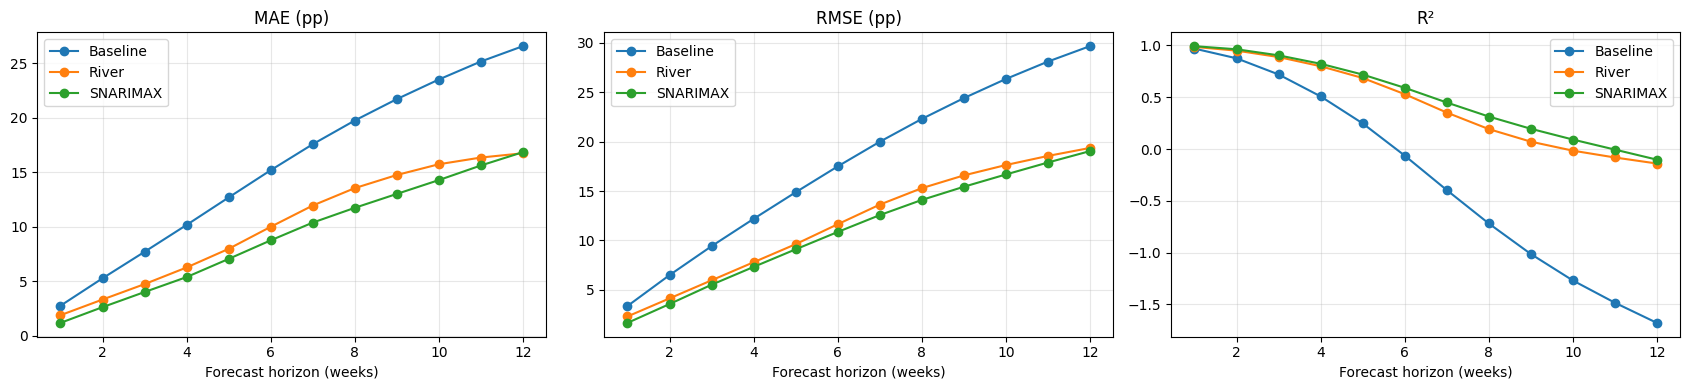

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for i, metric in enumerate(["MAE (pp)", "RMSE (pp)", "R²"]):

    for model_name, group in metrics_df.groupby("Model"):

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            label=model_name
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

SNARIMAX is competitive: The seasonal components appear to make a positive contribution across several horizons.



Both models outperform the baseline: This is a good sign that the models are learning more than simply carrying forward the most recent observed value.



Both encounter difficulties in the long term: R² turns negative around weeks 11–12.

Create a simple parameter search function for SNARIMAX, which evaluates different configurations using MAE, RMSE and R² over 12 forecast weeks.

In [14]:
from src.forecasting import tune_snarimax

tuning_results, best_params = tune_snarimax(
    df=df_region,
    horizon=12,
    val_weeks=52,
    origin_step=4
)

display(tuning_results.round(4))

print("Best parameters:", best_params)

1/8 completed
2/8 completed
3/8 completed
4/8 completed
5/8 completed
6/8 completed
7/8 completed
8/8 completed


,p,d,q,m,sp,sd,sq,MAE (pp),RMSE (pp),R²,N predictions
0,1,1,2,52,2,0,0,5.5809,6.7140,0.8183,132
1,1,1,1,52,2,0,0,5.6825,6.8275,0.8121,132
2,2,1,2,52,2,0,0,5.6761,6.8645,0.8100,132
3,2,1,1,52,2,0,0,5.8270,7.0604,0.7990,132
4,1,1,2,52,1,0,0,5.9636,7.3068,0.7848,132
5,1,1,1,52,1,0,0,6.0961,7.4071,0.7788,132
6,2,1,2,52,1,0,0,6.1407,7.4882,0.7739,132
7,2,1,1,52,1,0,0,6.2166,7.5948,0.7674,132


Best parameters: {'p': 1, 'd': 1, 'q': 2, 'm': 52, 'sp': 2, 'sd': 0, 'sq': 0}


In [20]:
predictions_test, metrics_test = evaluate_forecasting_models(
    df=df_region,
    horizon=12,
    test_weeks=52,
    n_lags=4,
    snarimax_params=best_params
)


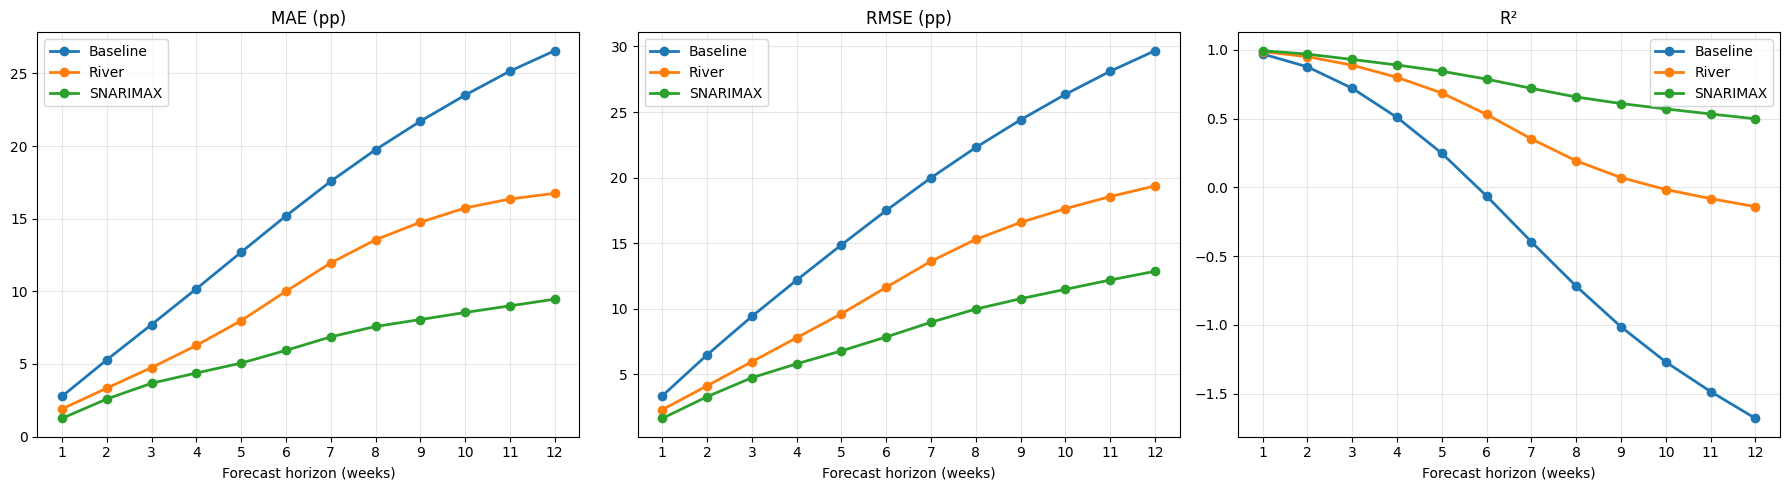

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE (pp)", "RMSE (pp)", "R²"]

for i, metric in enumerate(metrics):

    for model_name, group in metrics_test.groupby("Model"):

        group = group.sort_values("Horizon")

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            linewidth=2,
            label=model_name
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].set_xticks(range(1, 13))
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

## Test set

In [25]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# 1. Prepare data
# ============================================================

df_plot = df_region.copy()
df_plot["dato_Id"] = pd.to_datetime(df_plot["dato_Id"])

df_plot = (
    df_plot.sort_values("dato_Id")
    .drop_duplicates("dato_Id")
    .reset_index(drop=True)
)

horizon = 12

# Select forecast origins from the final test year
test_start = df_plot["dato_Id"].max() - pd.Timedelta(weeks=52)

seasons = {
    "Winter": [12, 1, 2],
    "Spring": [3, 4, 5],
    "Summer": [6, 7, 8],
    "Autumn": [9, 10, 11]
}

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=list(seasons.keys()),
    vertical_spacing=0.15
)

results = []

# ============================================================
# 2. Forecast each season
# ============================================================

for i, (season, months) in enumerate(seasons.items()):

    candidates = df_plot[
        (df_plot["dato_Id"] >= test_start) &
        (df_plot["dato_Id"].dt.month.isin(months)) &
        (df_plot["dato_Id"] <= df_plot["dato_Id"].max() - pd.Timedelta(weeks=horizon))
    ]

    if candidates.empty:
        print(f"No complete 12-week forecast available for {season}")
        continue

    # Choose the first available origin in the season
    forecast_start = candidates["dato_Id"].iloc[0]

    df_train = df_plot[
        df_plot["dato_Id"] <= forecast_start
    ].copy()

    forecast = forecast_reservoir_snarimax(
        df=df_train,
        horizon=horizon,
        **best_params
    )

    comparison = forecast.merge(
        df_plot[["dato_Id", "fyllingsgrad"]],
        left_on="date",
        right_on="dato_Id",
        how="inner"
    )

    if len(comparison) != horizon:
        print(f"Incomplete observations for {season}")
        continue

    y_true = comparison["fyllingsgrad"].to_numpy()
    y_pred = comparison["predicted"].to_numpy()

    results.append({
        "Season": season,
        "Forecast start": forecast_start,
        "MAE (pp)": mean_absolute_error(y_true, y_pred) * 100,
        "RMSE (pp)": np.sqrt(mean_squared_error(y_true, y_pred)) * 100,
        "R²": r2_score(y_true, y_pred)
    })

    row = i // 2 + 1
    col = i % 2 + 1

    # Actual
    fig.add_trace(
        go.Scatter(
            x=comparison["date"],
            y=comparison["fyllingsgrad"] * 100,
            mode="lines+markers",
            name="Actual",
            line=dict(color="green"),
            showlegend=(i == 0)
        ),
        row=row,
        col=col
    )

    # Predicted
    fig.add_trace(
        go.Scatter(
            x=comparison["date"],
            y=comparison["predicted"] * 100,
            mode="lines+markers",
            name="SNARIMAX",
            line=dict(color="darkorange", dash="dash"),
            showlegend=(i == 0)
        ),
        row=row,
        col=col
    )

# ============================================================
# 3. Show results
# ============================================================

fig.update_layout(
    title="SNARIMAX – 12-Week Forecast by Season",
    template="plotly_white",
    height=750,
    hovermode="x unified"
)

fig.update_yaxes(title_text="Reservoir filling (%)")

fig.show()

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Season,Forecast start,MAE (pp),RMSE (pp),R²
0,Winter,2025-12-07,11.5752,14.6454,0.0246
1,Spring,2026-03-01,2.7016,3.0733,0.1999
2,Summer,2026-06-07,7.5785,8.0849,-2.7160
3,Autumn,2025-11-16,10.6986,13.2381,-0.1622


In [26]:
dates = (
    pd.to_datetime(df_region["dato_Id"])
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

print("Validation:", dates.iloc[-105], "to", dates.iloc[-53])
print("Test:      ", dates.iloc[-52], "to", dates.iloc[-1])

Validation: 2024-11-17 00:00:00 to 2025-11-16 00:00:00
Test:       2025-11-23 00:00:00 to 2026-11-15 00:00:00


## Future forecast

In [23]:
import plotly.graph_objects as go

from src.forecasting import forecast_reservoir_snarimax

# ============================================================
# 1. Forecast with best SNARIMAX parameters
# ============================================================

forecast_snarimax = forecast_reservoir_snarimax(
    df=df_region,
    horizon=12,
    **best_params
)

display(forecast_snarimax)


# ============================================================
# 2. Plot historical filling and forecast
# ============================================================

df_plot = df_region.sort_values("dato_Id").tail(52)

fig = go.Figure()

# Historical filling
fig.add_trace(go.Scatter(
    x=df_plot["dato_Id"],
    y=df_plot["fyllingsgrad"] * 100,
    mode="lines",
    name="Historical filling",
    line=dict(color="royalblue", width=2)
))

# SNARIMAX forecast
fig.add_trace(go.Scatter(
    x=forecast_snarimax["date"],
    y=forecast_snarimax["predicted"] * 100,
    mode="lines+markers",
    name="SNARIMAX forecast",
    line=dict(color="darkorange", dash="dash", width=2)
))

# Mark forecast start
fig.add_vline(
    x=df_plot["dato_Id"].iloc[-1],
    line_dash="dot",
    line_color="gray"
)

fig.update_layout(
    title="Reservoir Filling – Best SNARIMAX 12-Week Forecast",
    xaxis_title="Date",
    yaxis_title="Reservoir filling (%)",
    template="plotly_white",
    hovermode="x unified",
    height=500
)

fig.show()

,date,predicted
0,2026-11-22,0.672344
1,2026-11-29,0.650915
2,2026-12-06,0.630400
3,2026-12-13,0.607218
4,2026-12-20,0.588846
5,2026-12-27,0.577653
6,2027-01-03,0.556006
7,2027-01-10,0.524215
8,2027-01-17,0.505523
9,2027-01-24,0.478248
